<a href="https://colab.research.google.com/github/lilyzhengliwang/Problem-Set-4/blob/main/Econ_3916_PS4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS4 — The Model That Fit Too Well

**ECON 3916 · Applied Data Analytics** · Topics 12-15 · 100 points · your role: Analyst, Revenue Forecasting

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is analyst's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. You fit the regressions, run the diagnostics and build the validation split yourself. AI is authorised and required in Phase 4.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

## Phase 1: Reproduce the 0.94 (30 pts)

### Step 1.1: Build the store panel (10 pts)

In [2]:
import statsmodels.api as sm

# What the brief fixes (Step 1.1). Keep it here so the grader can rerun you.
N_STORES = 400               # at least 400 stores
# predictors: floor area, foot traffic, local median income, years open,
# several that are irrelevant, and one that is nearly a linear combination of two others

In [3]:
n = N_STORES

# real predictors
floor_area = rng.lognormal(np.log(2000), 0.4, n)
foot_traffic = rng.lognormal(np.log(30), 0.4, n)
income = np.clip(rng.normal(65, 15, n), 25, None)
years_open = rng.integers(1, 26, n)

# nearly collinear
staff_hours = 0.02 * floor_area + 0.8 * foot_traffic + rng.normal(0, 1, n)

# irrelevant predictors
birth_month = rng.integers(1, 13, n)
shoe_size = rng.normal(10, 1.5, n).round(1)
favorite_number = rng.integers(1, 1000, n)

# revenue

floor_effect = 0.05 * floor_area - 0.035 * np.maximum(floor_area - 2500, 0)
mean_rev = 50 + floor_effect + 4.0 * foot_traffic + 0.8 * income + 2.0 * years_open
noise_sd = 0.035 * mean_rev
revenue = mean_rev + rng.normal(0, noise_sd)


In [4]:
stores = pd.DataFrame({"revenue": revenue, "floor_area": floor_area,
                       "foot_traffic": foot_traffic,"income": income,
                       "years_open": years_open, "staff_hours": staff_hours,
                       "shoe_size": shoe_size, "birth_month": birth_month,
                       "favorite_number":favorite_number,})

stores.head()

,revenue,floor_area,foot_traffic,income,years_open,staff_hours,shoe_size,birth_month,favorite_number
0,355.210,2259.253,27.920,52.324,11,68.124,10.5,3,59
1,300.005,1319.369,32.457,48.745,6,52.170,9.9,7,50
2,415.642,2700.205,41.654,70.169,3,87.903,9.2,12,482
3,351.703,2913.552,25.628,70.689,11,77.364,13.3,2,404
4,364.703,916.432,36.954,84.310,14,49.074,9.3,2,850


*The data-generating process, recorded: every predictor and the true revenue equation.*

Recording data process

true revenue equation: 50 + floor_effect + 4.0 * foot_traffic + 0.8 * income + 2.0 * years_open

* Real predictors: floor area, foot traffic, income, years open (coefficients in the rev equation)

* diminishing returns - floor's area drops from 0.05 to 0.015 above 2500 sq ft
* growing spread - noise is 3.5% of each store's expected revenue; bigger stores will scatter more
* near collinear predictor is staff hours because it is from floor area and foot traffic
* irrelevant factors: birth month of manager, shoe size of manager, favorite number of manager

### Step 1.2: Fit it the way they did (12 pts)

In [5]:
# fit OLS with all predictors
X_cols = [c for c in stores.columns if c != 'revenue']

full = sm.OLS(stores['revenue'], sm.add_constant(stores[X_cols])).fit()
print("R-squred on all data:", round(full.rsquared, 3))

R-squred on all data: 0.94


In [6]:
# r-squared on data the model never saw
idx = rng.permutation(N_STORES)
train, test = stores.iloc[idx[:300]], stores.iloc[idx[300:]]

m = sm.OLS(train["revenue"], sm.add_constant(train[X_cols])).fit()
pred = m.predict(sm.add_constant(test[X_cols], has_constant="add"))
r2_test = 1 - ((test["revenue"] - pred) ** 2).sum() / ((test["revenue"] - test["revenue"].mean()) ** 2).sum()

print("R-squared (train):", round(m.rsquared, 3))
print("R-squared (held-out):", round(r2_test, 3))
print("gap:", round(m.rsquared - r2_test, 3))

R-squared (train): 0.94
R-squared (held-out): 0.937
gap: 0.004


The R-squared on all the predictors is 0.94. The R-squared on data that the model didn't see is 0.937, with a -0.004 gap compared to the R-squared of all.


### Step 1.3: Say what R-squared is (8 pts)

In-sample r-squared cannot fall decrease when you add a predictors because OLS chooses the coefficients so that it minimizes the sum of the squared residuals, and even useless predictors will always have some chance small correlation so that it will always decrease R-squared slightly or at least stay the same. Since r-squared measures how well the model fits to the data that it was fit to, it is not very helpful for choosing between models; the biggest model always wins.

In [7]:
# adding pure noise

noise = pd.DataFrame(rng.normal(size=(N_STORES, 3)), columns=["noise1", "noise2", "noise3"])
with_noise = pd.concat([stores, noise], axis=1)
cols2 = X_cols + list(noise.columns)
m2 = sm.OLS(with_noise["revenue"], sm.add_constant(with_noise[cols2])).fit()

print("Before: R-squared %.6f  adj R-squared %.6f" % (full.rsquared, full.rsquared_adj))
print("After:  R-squared %.6f  adj R-squared %.6f" % (m2.rsquared, m2.rsquared_adj))

Before: R-squared 0.939948  adj R-squared 0.938719
After:  R-squared 0.940032  adj R-squared 0.938332


After adding three columns of random noise, the R-squared rose slightly, as expected because of very small incremental gains that usually happen when you add anything. The adjusted R-squared fell slightly, meaning that the noise columns added less than the penalty for including them.

## Phase 2: Diagnose the Failure (35 pts)

### Step 2.1: Look at the residuals (20 pts)

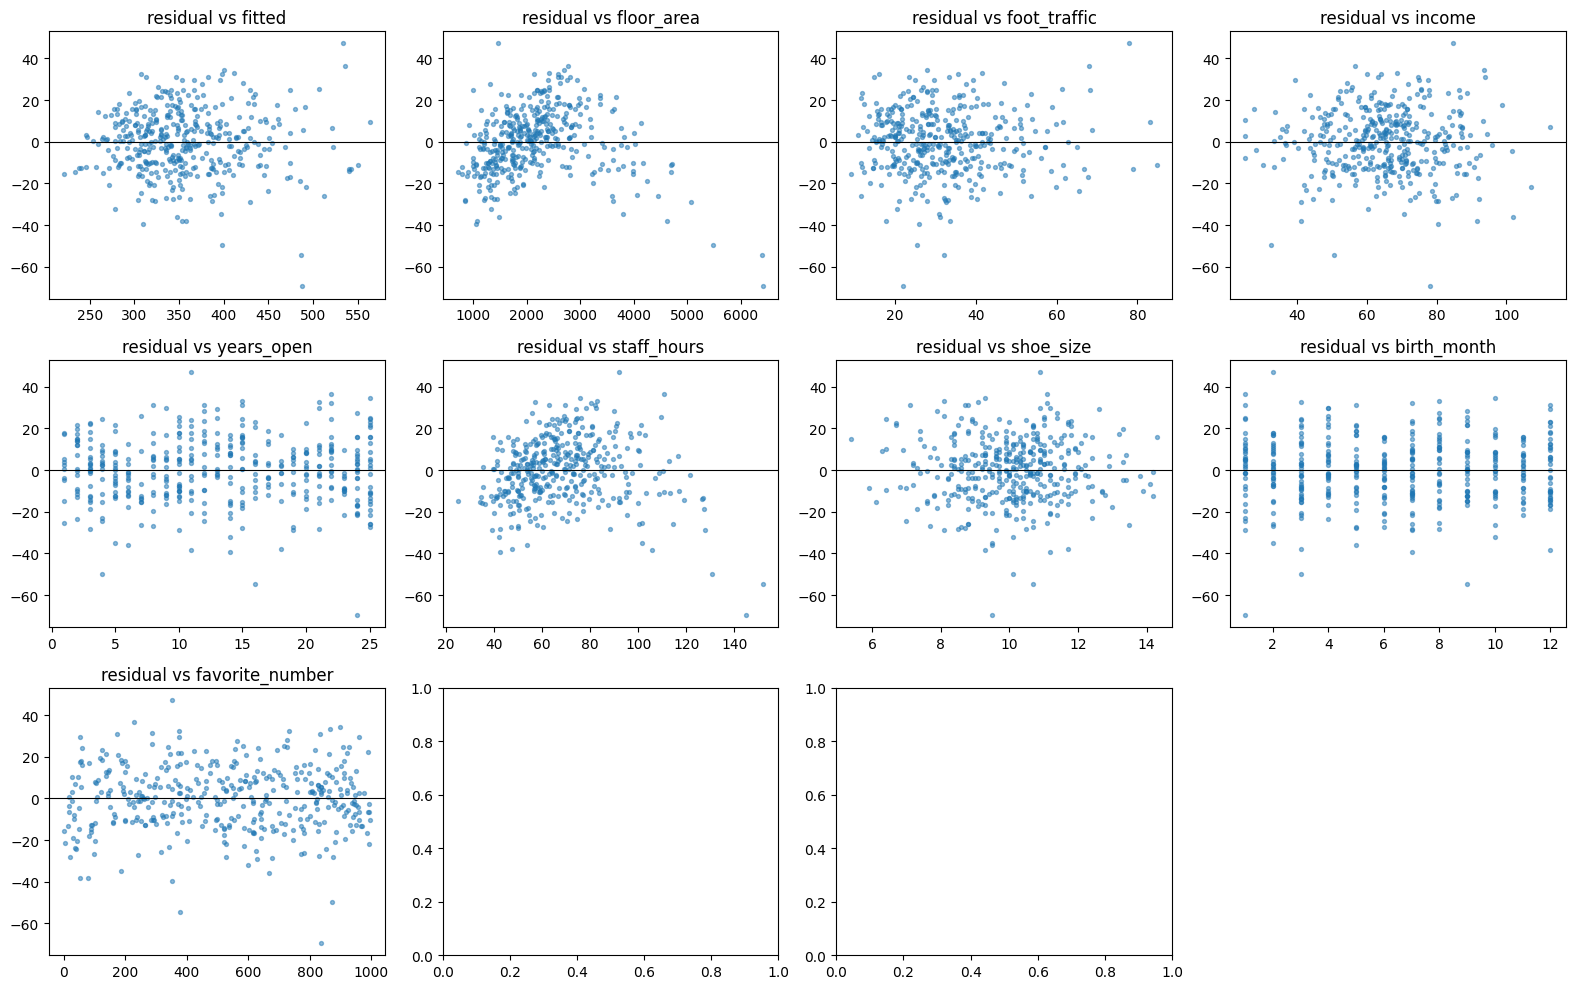

Breusch-Pagan p: 4.3468747511044745e-09
(221.567, 312.987]    12.471
(312.987, 348.538]    14.904
(348.538, 390.426]    15.069
(390.426, 563.288]    18.775
dtype: float64
floor_area
(716.399, 1228.011]    -10.642
(1228.011, 1421.786]    -7.619
(1421.786, 1656.169]    -1.316
(1656.169, 1815.676]    -2.331
(1815.676, 2013.789]     0.147
(2013.789, 2195.149]     4.938
(2195.149, 2386.373]     7.714
(2386.373, 2714.426]    12.355
(2714.426, 3271.583]     7.582
(3271.583, 6415.341]   -10.828
dtype: float64
max Cook's D: 0.23203665967989165 | above 4/n: 20


In [8]:
# plot residuals

from statsmodels.stats.diagnostic import het_breuschpagan

resid, fitted = full.resid, full.fittedvalues

# residuals vs fitted
cols = ["fitted"] + X_cols
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, c in zip(axes.flat, cols):
    ax.scatter(fitted if c == "fitted" else stores[c], resid, s=8, alpha=.5)
    ax.axhline(0, color="k", lw=.8); ax.set_title(f"residual vs {c}")
axes.flat[-1].axis("off"); plt.tight_layout(); plt.show()

# non constant variance
print("Breusch-Pagan p:", het_breuschpagan(resid, sm.add_constant(stores[X_cols]))[1])
print(resid.groupby(pd.qcut(fitted, 4), observed=True).std())

# non-linear relationship missed (floor area)
print(resid.groupby(pd.qcut(stores["floor_area"], 10), observed=True).mean())

# influence
cd = full.get_influence().cooks_distance[0]
print("max Cook's D:", cd.max(), "| above 4/n:", (cd > 4 / N_STORES).sum())

In the plots we can see non-linear relationships that the model missed; you see it in the plots for floor area and staff hours. You can see that the mean residual by floor area decile goes from -10.6 to 12.4 and then back down to -10.8. The assumption that it violates is correct functional form. This will bias the estimate, and the SE will not be relevant because the estimate is biased. Non-constant variance is not very obvious in the plots, but we can still see a mild fan in the residual vs fitted plot, and its low p-value for Breusch-Pagan test shows that. This does not affect the estimate, but the SE will be inaccurate.

### Step 2.2: The over-forecast on big stores (15 pts)

In [9]:
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif

# quantify overforecast
stores["err"] = full.fittedvalues - stores["revenue"]
stores["pct"] = stores["err"] / stores["revenue"] * 100
dec = pd.qcut(stores["floor_area"], 10, labels=range(1, 11))
print(stores.groupby(dec, observed=True).agg(area=("floor_area", "median"), rev=("revenue", "mean"),
      mean_err=("err", "mean"), pct_err=("pct", "mean"), share_over=("err", lambda x: (x > 0).mean())).round(1))

for name, mask in [("top decile", dec == 10), ("area > 3500", stores["floor_area"] > 3500)]:
    s = stores[mask]; t = stats.ttest_1samp(s["err"], 0)
    print(f"{name}: n={len(s)} mean over-forecast {s['err'].mean():.1f}k ({s['pct'].mean():.1f}%) t={t.statistic:.2f} p={t.pvalue:.4f}")

# vif
X = sm.add_constant(stores[X_cols])
print(pd.Series([vif(X.values, i) for i in range(1, X.shape[1])], index=X_cols).round(1))

              area    rev  mean_err  pct_err  share_over
floor_area                                              
1           1074.7  321.2      10.6      3.7         0.8
2           1330.2  318.0       7.6      2.6         0.7
3           1530.8  347.5       1.3      0.7         0.6
4           1727.9  346.4       2.3      0.7         0.5
5           1893.1  347.4      -0.1      0.1         0.4
6           2127.1  342.5      -4.9     -1.4         0.3
7           2291.0  362.1      -7.7     -2.2         0.2
8           2542.3  378.6     -12.4     -3.2         0.2
9           2891.6  389.9      -7.6     -1.7         0.3
10          3808.5  409.3      10.8      2.8         0.8
top decile: n=40 mean over-forecast 10.8k (2.8%) t=3.32 p=0.0020
area > 3500: n=33 mean over-forecast 14.2k (3.7%) t=4.03 p=0.0003
floor_area         289.9
foot_traffic       109.8
income               1.0
years_open           1.0
staff_hours        386.2
shoe_size            1.0
birth_month          1.0
favorite_n

The biggest stores are over-forecast; the top decile (40 stores total) is over-forecast by \$10.8k per month on average. For stores that are over 3500 sq ft, it is \$14.2k.

VIF flagged three variables - floor_area, foot_traffic, and staff_hours; floor_area VIF = 290, foot_traffic VIF = 110, staff_hours VIF = 386. High VIF damages the SE of the collinear coefficients; for prediction it is okay to keep them, but for causal inference this will significantly damage it.

## Phase 3: Build Something Honest (25 pts)

### Step 3.1: The complexity sweep (14 pts)

                 model  n_params  train_RMSE  heldout_RMSE
0         1 floor_area         2        57.8          57.6
1      2 +foot_traffic         3        23.3          24.0
2            3 +income         4        20.7          21.4
3        4 +years_open         5        15.4          15.8
4      5 all 10 linear         9        15.3          16.0
5    6 real, quadratic        15        12.5          13.5
6        7 real, cubic        35        11.8          13.9
7  8 all 10, quadratic        45        11.8          14.4
8      9 all 10, cubic       165         8.4          26.6


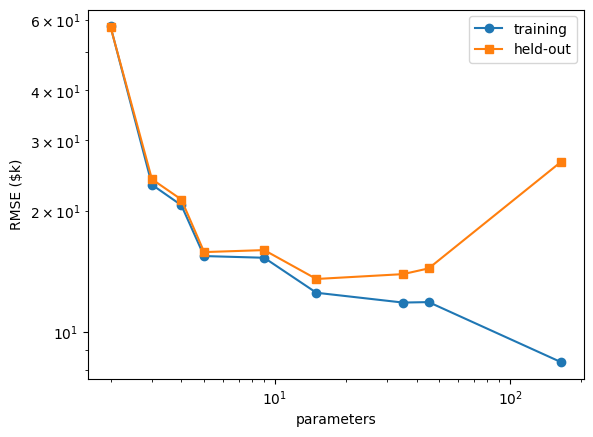

In [10]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

real = ["floor_area", "foot_traffic", "income", "years_open"]
models = [("1 floor_area", ["floor_area"], 1), ("2 +foot_traffic", real[:2], 1),
          ("3 +income", real[:3], 1), ("4 +years_open", real, 1),
          ("5 all 10 linear", X_cols, 1), ("6 real, quadratic", real, 2),
          ("7 real, cubic", real, 3), ("8 all 10, quadratic", X_cols, 2),
          ("9 all 10, cubic", X_cols, 3)]

y = stores["revenue"].values
splits = [rng.permutation(N_STORES) for _ in range(100)]
rows = []
for label, cols, deg in models:
    Xm, tr_e, te_e = stores[cols].values, [], []
    for p in splits:
        tr, te = p[:300], p[300:]
        mdl = make_pipeline(StandardScaler(), PolynomialFeatures(deg, include_bias=False),
                            StandardScaler(), LinearRegression()).fit(Xm[tr], y[tr])
        tr_e.append(np.sqrt(np.mean((y[tr] - mdl.predict(Xm[tr])) ** 2)))
        te_e.append(np.sqrt(np.mean((y[te] - mdl.predict(Xm[te])) ** 2)))
    rows.append((label, mdl[2].n_features_in_ + 1, np.median(tr_e), np.median(te_e)))

res = pd.DataFrame(rows, columns=["model", "n_params", "train_RMSE", "heldout_RMSE"])
print(res.round(1))

plt.plot(res.n_params, res.train_RMSE, "o-", label="training")
plt.plot(res.n_params, res.heldout_RMSE, "s-", label="held-out")
plt.xscale("log"); plt.yscale("log"); plt.xlabel("parameters"); plt.ylabel("RMSE ($k)")
plt.legend(); plt.show()

Held out error falls through model 6 and then rises, so that marks the turn. In bias-variance terms, the left half is high bias low variance, and the right half is low bias high variance.

### Step 3.2: Choose, and be honest about the estimate (11 pts)

In [11]:
from sklearn.model_selection import KFold
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

def make(deg):
    return make_pipeline(StandardScaler(), PolynomialFeatures(deg, include_bias=False),
                         StandardScaler(), LinearRegression())

def cv_sse(idx, cols, deg, k, seed):
    Xm, sse = stores[cols].values, 0.0
    for tr, te in KFold(k, shuffle=True, random_state=seed).split(idx):
        m = make(deg).fit(Xm[idx[tr]], y[idx[tr]])
        sse += ((y[idx[te]] - m.predict(Xm[idx[te]])) ** 2).sum()
    return sse

all_idx = np.arange(N_STORES)

# naive (pick the model with the lowest 5-fold CV error on all data)
naive = {lab: np.sqrt(np.mean([cv_sse(all_idx, c, d, 5, s) for s in range(5)]) / N_STORES)
         for lab, c, d in models}
print(naive)

# nested (repeat procedure inside each outer training set)
def nested(seed):
    pred = np.zeros(N_STORES)
    for tr, te in KFold(5, shuffle=True, random_state=seed).split(all_idx):
        j = int(np.argmin([cv_sse(tr, c, d, 5, seed) for _, c, d in models]))
        _, c, d = models[j]
        pred[te] = make(d).fit(stores[c].values[tr], y[tr]).predict(stores[c].values[te])
    return pred

preds = [nested(s) for s in range(5)]
e2 = np.mean([(y - p) ** 2 for p in preds], axis=0)             # per-store squared error
boot = [np.sqrt(e2[rng.integers(0, N_STORES, N_STORES)].mean()) for _ in range(5000)]
print("nested RMSE", np.sqrt(e2.mean()), "95% interval", np.percentile(boot, [2.5, 97.5]))

{'1 floor_area': np.float64(58.03597708643366), '2 +foot_traffic': np.float64(23.683680716501843), '3 +income': np.float64(21.14737848009758), '4 +years_open': np.float64(15.856297829388309), '5 all 10 linear': np.float64(15.967077766110696), '6 real, quadratic': np.float64(13.394508118302765), '7 real, cubic': np.float64(14.016228980534525), '8 all 10, quadratic': np.float64(14.130874877433385), '9 all 10, cubic': np.float64(28.11537197433535)}
nested RMSE 13.58212934555728 95% interval [12.59814573 14.55705636]


The CV score of the winning model isn't an unbiased estimate of its error. Each of the nine models gets a noisy CV score, and picking the lowest one favors a model whose score got lucky. The same data both chose the model and graded it, so the test folds influenced the choice.

**what the number is & isn't**

The reported number is an estimate of the error that you would get by running this procedure on stores drawn from the same population as these 400. It is not a forecast for the next month or an accurate estimate for every store. It will not be the same for unseen data.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

def analyze_learning_curve(model, X, y, cv=5):
    """
    Computes and plots learning curves to diagnose bias vs. variance.
    """
    train_sizes, train_scores, val_scores = learning_curve(
        estimator=model,
        X=X,
        y=y,
        cv=cv,
        scoring='neg_mean_squared_error',
        train_sizes=np.linspace(0.1, 1.0, 10),
        n_jobs=-1
    )

    # Convert negative MSE to positive error (e.g., MSE or RMSE)
    train_error = -train_scores
    val_error = -val_scores

    train_mean = np.mean(train_error, axis=1)
    train_std = np.std(train_error, axis=1)
    val_mean = np.mean(val_error, axis=1)
    val_std = np.std(val_error, axis=1)

    plt.figure(figsize=(9, 6))

    # --- MECHANISM CHECK: THE GAP VS. THE LEVEL ---
    # 1. THE GAP (Variance Indicator):
    #    A wide gap between training error and validation error indicates HIGH VARIANCE.
    #    The model is memorizing the training set noise rather than generalizing.
    #    Implication: Collecting more training data will help bridge this gap.
    #
    # 2. THE LEVEL (Bias Indicator):
    #    The error rate/value where both curves converge at maximum data size indicates HIGH BIAS.
    #    If the converged error is unacceptably high, the model (or your 12 predictors)
    #    lacks the capacity to capture the true underlying revenue patterns.
    #    Implication: Collecting more data of the *same* kind will NOT help;
    #    you need better features or a more expressive model.

    plt.plot(train_sizes, train_mean, 'o-', color='crimson', label='Training Error')
    plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std,
                     alpha=0.15, color='crimson')

    plt.plot(train_sizes, val_mean, 'o-', color='dodgerblue', label='Validation Error')
    plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std,
                     alpha=0.15, color='dodgerblue')

    plt.title('Store Revenue Regression: Learning Curves', fontsize=12, fontweight='bold')
    plt.xlabel('Training Set Size (Number of Stores)', fontsize=10)
    plt.ylabel('Mean Squared Error (MSE)', fontsize=10)
    plt.legend(loc='upper right', fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

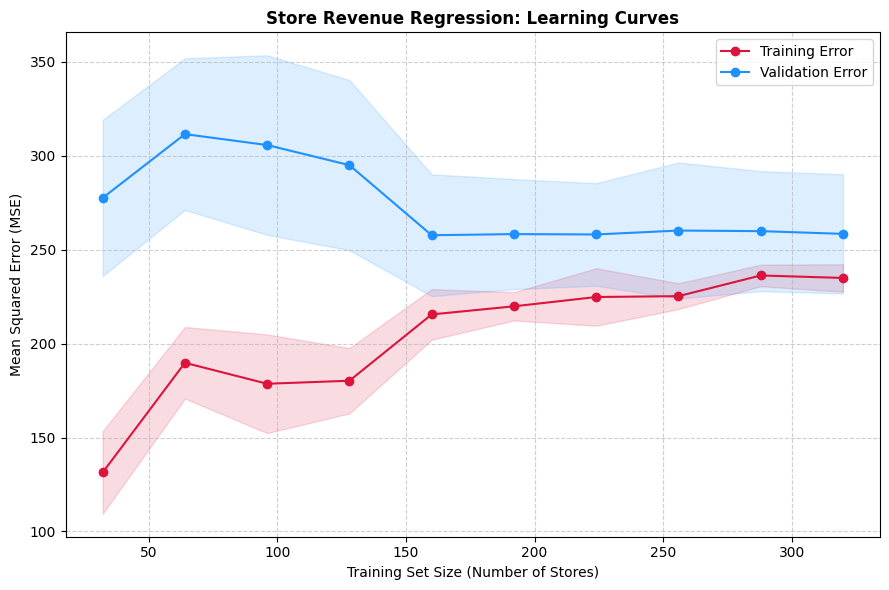

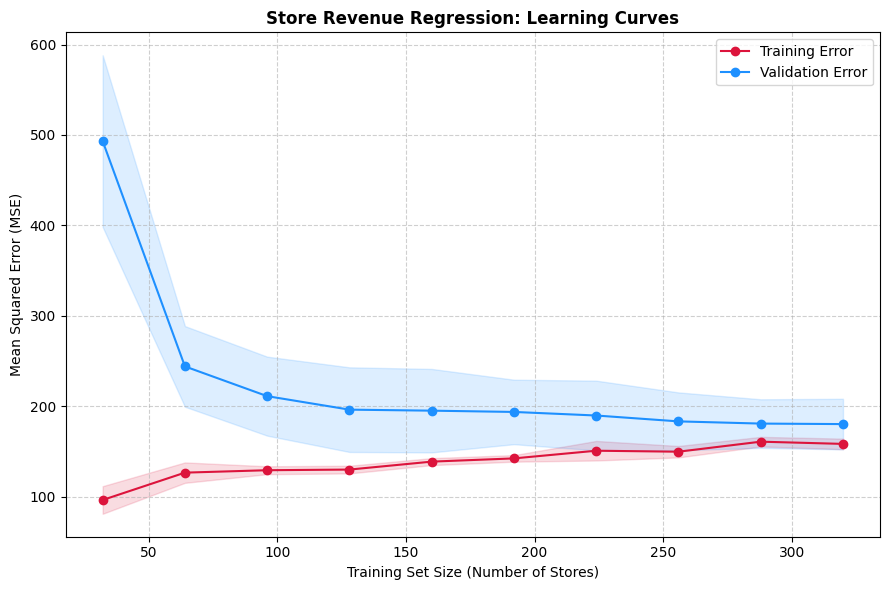

In [13]:
def make(deg):
    return make_pipeline(StandardScaler(), PolynomialFeatures(deg, include_bias=False),
                         StandardScaler(), LinearRegression())

y = stores["revenue"].values
real = ["floor_area", "foot_traffic", "income", "years_open"]


analyze_learning_curve(make(1), stores[X_cols].values, y)
analyze_learning_curve(make(2), stores[real].values, y)

### Task 4.1: The learning curve (4 pts)

The learning curves agree with Phase 3 diagnosis. The inherited linear model is bias-limited; its train and validation curves meet and flatten so more stores won't help.

### Task 4.2: What "validated" meant (3 pts)

> **No AI on this task, and no transcript.** Here you are the reviewer.

The departing analyst's cell, copied from the brief. For (b), run it as it is with 300 pure-noise columns alone as `X` and your Phase 1 revenue as `y`.

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

X_scaled = StandardScaler().fit_transform(X)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y)
scores = cross_val_score(LinearRegression(), X_sel, y, cv=5, scoring="r2")
print(f"Validated R^2: {scores.mean():.2f}")

Validated R^2: 0.93


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=20 is greater than n_features=9. All the features will be returned.
  warnings.warn(


In [15]:
from sklearn.pipeline import Pipeline
y = stores["revenue"].values
X = rng.normal(size=(N_STORES, 300))

# analyst cell
X_scaled = StandardScaler().fit_transform(X)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y)
scores = cross_val_score(LinearRegression(), X_sel, y, cv=5, scoring="r2")
print(f"Validated R^2: {scores.mean():.2f}")

# Same steps refitted inside each fold
pipe = Pipeline([("scale", StandardScaler()),
                 ("select", SelectKBest(f_regression, k=20)),
                 ("ols", LinearRegression())])
print(f"Pipeline R^2:  {cross_val_score(pipe, X, y, cv=5, scoring='r2').mean():.2f}")

Validated R^2: 0.17
Pipeline R^2:  -0.14


(a) SelectKBest(f_regression) is the one that inflates it; it uses y fitted on all 400 stores and picks the 20 columns that happen to correlate best with revenue over every row, including ones that later serve as validation folds. StandardScaler is harmless for OLS with an intercept because it only uses X but not y, so it shifts and rescales each column. OLS with an intercept is not change by that, since the intercept will absorb shifts and coefficient will absorb rescaling.

(b) The analyst's cell reports 0.17 for 300 columns of pure noise while the pipeline gives -0.14, with a gap of 0.31. The pipeline value is negative because the selected columns only fit chance correlations in each training fold; the gap is the leak from SelectKBest choosing columns using all the data's revenue values before the folds were made.

(c) This is a somewhat special case of step 3.2's problem, where data used to mae a choice also scores it.

### Task 4.3: The handover note (3 pts)

## Handover note: store revenue model

**What it predicts.** Monthly revenue per store ($k) from floor area, foot traffic, local median income and years open, with a quadratic floor-area term for diminishing returns. The other columns in the old model carried no signal.

**What "0.94" meant.** In-sample R², which can only rise as columns are added. It never tested forecasting, and the old straight-line fit over-forecast the largest stores by about $14k a month.

**Honest error.** Nested cross-validation (selection repeated inside each fold) gives an RMSE of **\$13.6k per store-month**, 95% interval **\$12.6k–\$14.6k**, about 3–4% of revenue. Error grows with size, to roughly $19k above 3,500 sq ft, so report it by size band, not as one number.

**It will fail when:**
1. **A store exceeds the sizes it was trained on.** Beyond roughly 4,500 sq ft, data are sparse and the quadratic extrapolates badly.
2. **The world shifts.** It was fit on one snapshot and never tested forward in time, so it gives no warning when traffic or income relationships change, as they did in July.

**What I would build next.** Score the model once on the latest months, held out in time. Replace the quadratic with a log or spline that flattens rather than turns down, and model log revenue so the growing spread is handled. Track error monthly by size band, alerting when large-store over-forecast returns.

### AI Transcript

Paste **your prompt exactly as you sent it** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date.

**Prompt**

[Prep] Act as a machine learning engineer who diagnoses model
performance problems in production.

[Request] I have a store-level revenue regression with 400 rows and
about 12 predictors. Write Python that produces a learning curve --
training and validation error as a function of training set size --
and interprets it to distinguish a high-bias problem from a
high-variance one.

[Iterate] scikit-learn, numpy and matplotlib. Reuse my X and y. Plot
both curves on one axis with a shaded band for variability across
folds.

[Mechanism Check] Add comments explaining what the GAP between the two
curves indicates versus what the LEVEL both converge to indicates, and
what each implies about whether collecting more data would help.

[Evaluate] Run it on my data and tell me whether more stores or better
features is the higher-return investment.

### AI Transcript
Gemini Auto - Nov 19, 3:18 a.m.

Here is the production-grade Python script to generate and analyze the learning curve for your store-level revenue regression model, along with a diagnostic evaluation tailored to your dataset dimensions.Learning Curve Implementation

`import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

def analyze_learning_curve(model, X, y, cv=5):
    """
    Computes and plots learning curves to diagnose bias vs. variance.
    """
    train_sizes, train_scores, val_scores = learning_curve(
        estimator=model,
        X=X,
        y=y,
        cv=cv,
        scoring='neg_mean_squared_error',
        train_sizes=np.linspace(0.1, 1.0, 10),
        n_jobs=-1
    )
    
    # Convert negative MSE to positive error (e.g., MSE or RMSE)
    train_error = -train_scores
    val_error = -val_scores
    
    train_mean = np.mean(train_error, axis=1)
    train_std = np.std(train_error, axis=1)
    val_mean = np.mean(val_error, axis=1)
    val_std = np.std(val_error, axis=1)
    
    plt.figure(figsize=(9, 6))
    
    # --- MECHANISM CHECK: THE GAP VS. THE LEVEL ---
    # 1. THE GAP (Variance Indicator):
    #    A wide gap between training error and validation error indicates HIGH VARIANCE.
    #    The model is memorizing the training set noise rather than generalizing.
    #    Implication: Collecting more training data will help bridge this gap.
    #
    # 2. THE LEVEL (Bias Indicator):
    #    The error rate/value where both curves converge at maximum data size indicates HIGH BIAS.
    #    If the converged error is unacceptably high, the model (or your 12 predictors)
    #    lacks the capacity to capture the true underlying revenue patterns.
    #    Implication: Collecting more data of the *same* kind will NOT help;
    #    you need better features or a more expressive model.
    
    plt.plot(train_sizes, train_mean, 'o-', color='crimson', label='Training Error')
    plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std,
                     alpha=0.15, color='crimson')
    
    plt.plot(train_sizes, val_mean, 'o-', color='dodgerblue', label='Validation Error')
    plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std,
                     alpha=0.15, color='dodgerblue')
    
    plt.title('Store Revenue Regression: Learning Curves', fontsize=12, fontweight='bold')
    plt.xlabel('Training Set Size (Number of Stores)', fontsize=10)
    plt.ylabel('Mean Squared Error (MSE)', fontsize=10)
    plt.legend(loc='upper right', fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()`

  Production Evaluation: 400 Rows & 12 Predictors

With 400 rows and 12 predictors, your dataset is exceptionally small for machine learning. Here is how to evaluate whether your next high-return investment should be more stores (data) or better features:

The Data Scarcity Bottleneck (High Variance Risk):

400 samples divided across 5-fold cross-validation means validation folds contain only ~80 stores. With 12 predictors, standard regression models or tree-based models can easily overfit local idiosyncrasies of specific stores (e.g., a single outlier manager or local event).

If your learning curve shows a large persistent gap where training error is low and validation error is high, more stores (data) is the higher-return investment. Tripling your store count to 1,200+ will stabilize variance.

The Feature Ceiling (High Bias Risk):

Revenue regression is notoriously noisy. If your 12 predictors consist only of basic store attributes (e.g., square footage, region, number of registers) while missing external drivers like local foot traffic, competitor proximity, neighborhood demographics, and local promotional calendars, your model will hit a hard error floor.

If your learning curve shows both training and validation errors flattening out at an unacceptably high level (converging together), better features is the mandatory first investment. No amount of data will fix missing predictive signal.

Recommendation

Look at the convergence point on your generated plot:

If the validation curve is still sloping downward steeply at
N
=
400
N=400 with a wide gap, collect more store data.

If the validation curve has flatlined high up, invest in feature engineering (geospatial data, localized economic indicators, historical sales lags) before expanding your sample size.

Want me to outline specific high-value features for store-level revenue forecasting?

*Model and date:*

*Prompt:*

*Reply:*

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; your prompt is in it as sent.
- [ ] Submit the Colab share link on Canvas (upload the `.ipynb` as a fallback).
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 4/Econ_3916_PS4.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.